# Project 2 – Neural network: latent space analysis
**Question:** how does the network transform the data on its way from input to output, and where do persons with prediabetes/diabetes end up?

We look at the representation after each layer, as in the Week 9 exercise:
input (21 features) → hidden layer 1 (32 units) → hidden layer 2 (16 units), and project each to 2-D with t-SNE, UMAP and PCA.

## 1. Load the trained model
We run `Project2_NN_clean.ipynb` with `%run` to get the trained `model` and the same data split. No new model is trained.
The cell takes a few minutes; its output is hidden (`main_log.show()` shows it).

In [1]:
%%capture main_log
%run Project2_NN_clean.ipynb

In [2]:
import warnings
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import balanced_accuracy_score
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import umap

plt.close('all')
warnings.filterwarnings('ignore', message='n_jobs value')
warnings.filterwarnings('ignore', message='compatibility_layout', category=FutureWarning)
SEED = 42

import torch
model.eval()
with torch.no_grad():
    test_proba = torch.sigmoid(model(torch.tensor(X_test, dtype=torch.float32))).numpy().ravel()
print(f'Test balanced accuracy of the loaded model: {balanced_accuracy_score(y_test, (test_proba >= 0.5).astype(int)):.3f}')

Test balanced accuracy of the loaded model: 0.746


## 2. Representations per layer

In [3]:
# Random sample of 5000 test persons (t-SNE/UMAP are slow on all ~50,000)
N_LATENT = 5000
lat_idx = np.random.default_rng(SEED).choice(len(X_test), size=N_LATENT, replace=False)
lat_y012 = y012_test[lat_idx]
print('Classes in the sample (0, 1, 2):', np.bincount(lat_y012))

# model.network = [Linear(21,32), ReLU, Linear(32,16), ReLU, Linear(16,1)]
X_lat_t = torch.tensor(X_test[lat_idx], dtype=torch.float32)
with torch.no_grad():
    reps = {
        'Input (21)': X_test[lat_idx],
        'Hidden 1 (32)': model.network[:2](X_lat_t).numpy(),
        'Hidden 2 (16)': model.network[:4](X_lat_t).numpy(),
    }

Classes in the sample (0, 1, 2): [4232   92  676]


In [4]:
pca_embs, pca_vars, tsne_embs, umap_embs = {}, {}, {}, {}
for name, R in reps.items():
    pca = PCA(n_components=2, random_state=SEED)
    pca_embs[name] = pca.fit_transform(R)
    pca_vars[name] = pca.explained_variance_ratio_
    tsne_embs[name] = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED).fit_transform(R)
    umap_embs[name] = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=SEED).fit_transform(R)
    print(f'{name:28s} done')

class_colors = {0: 'lightgray', 1: '#0070e0', 2: '#e06c00'}
class_labels = {0: 'No diabetes (0)', 1: 'Prediabetes (1)', 2: 'Diabetes (2)'}


def scatter_by_label(ax, emb, title, xlabel, ylabel, legend=False):
    for c in [0, 2, 1]:   # big class first, so the small classes stay visible on top
        m = lat_y012 == c
        ax.scatter(emb[m, 0], emb[m, 1], s=4, alpha=0.6, color=class_colors[c], label=f'{class_labels[c]}  n={m.sum()}')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.tick_params(labelsize=8)
    if legend:
        ax.legend(markerscale=3, fontsize=7)

Input (21)                   done


Hidden 1 (32)                done


Hidden 2 (16)                done


## 3. t-SNE and UMAP per layer

*Reading the axes:* t-SNE 1/2 and UMAP 1/2 have **no unit and no meaning** on their own: they are not features, and the numbers change with the random seed. Only *which points lie close to each other* can be interpreted, not the position on an axis or the distance between far-apart groups. PCA axes (Section 4) do have a meaning: a fixed linear combination of the features.

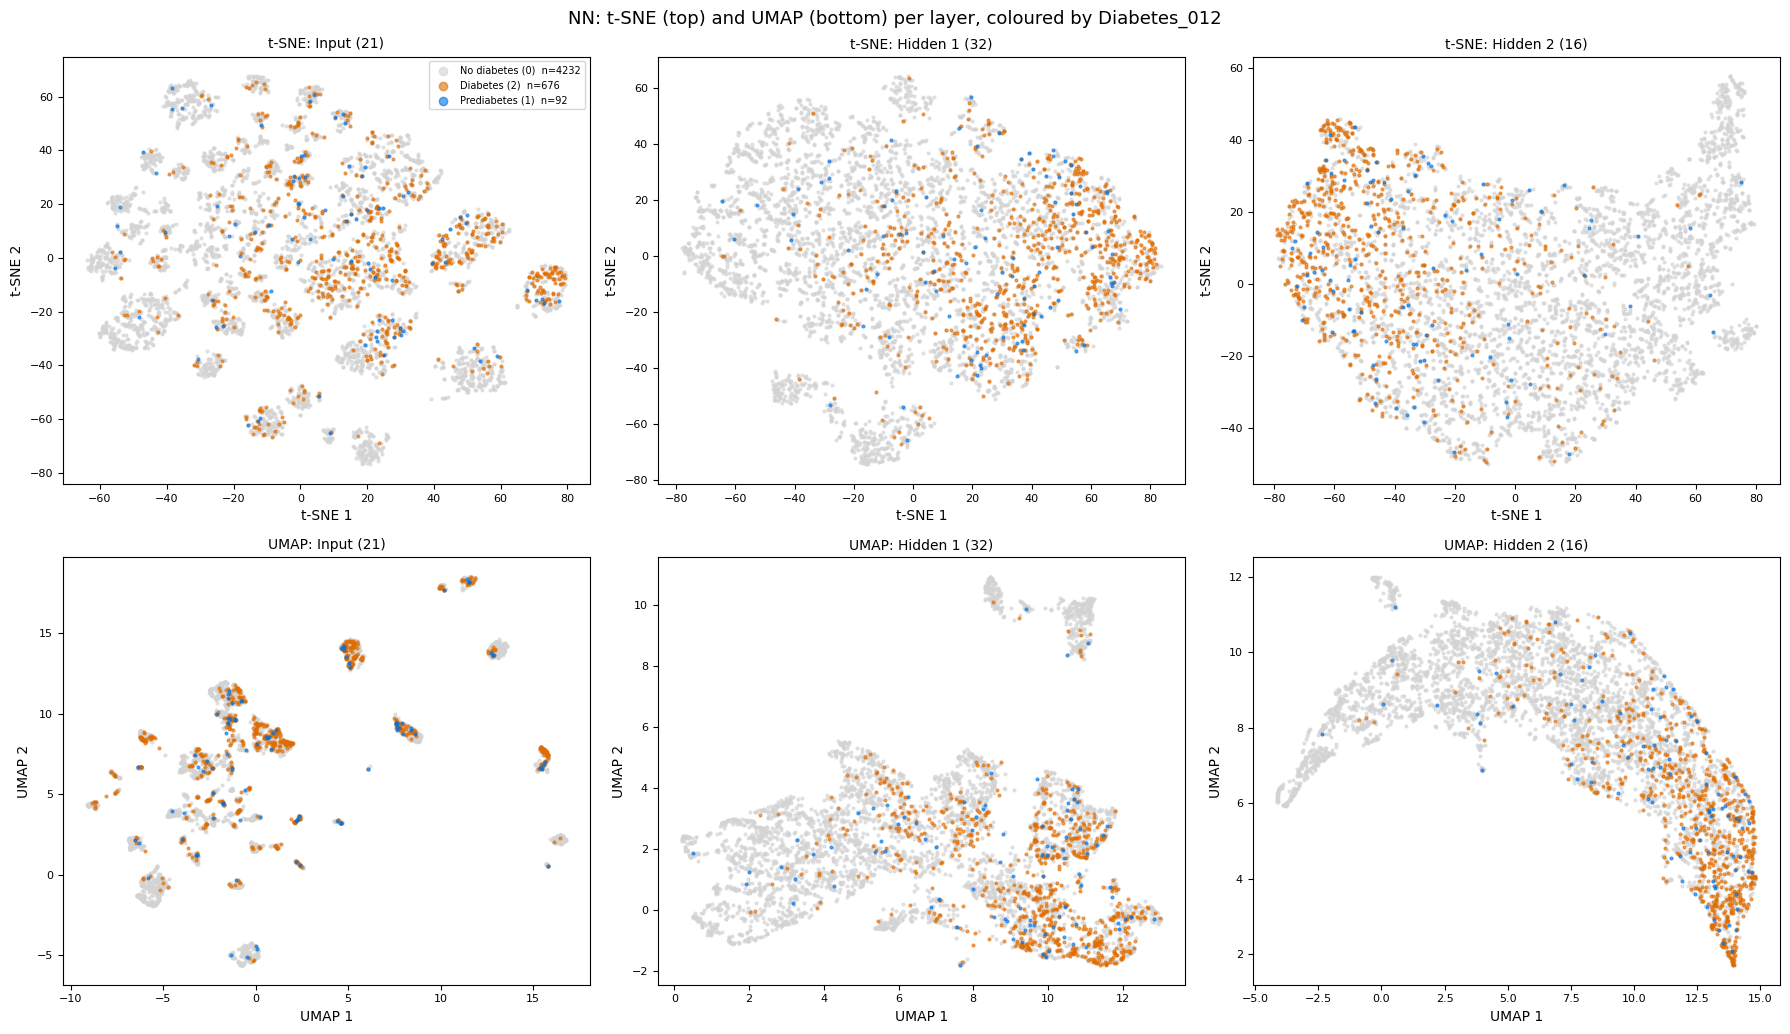

In [5]:
fig, axes = plt.subplots(2, len(reps), figsize=(6 * len(reps), 10.5))
for i, name in enumerate(reps):
    scatter_by_label(axes[0, i], tsne_embs[name], f't-SNE: {name}', 't-SNE 1', 't-SNE 2', legend=(i == 0))
    scatter_by_label(axes[1, i], umap_embs[name], f'UMAP: {name}', 'UMAP 1', 'UMAP 2')
fig.suptitle(f'{MODEL_TAG}: t-SNE (top) and UMAP (bottom) per layer, coloured by Diabetes_012', fontsize=13)
plt.tight_layout()
plt.show()

**Analysis**
- **Input:** both methods show many small, separate islands. The features are mostly binary (yes/no) or few-level ordinal, so persons with the same combination of answers lie on top of each other. Diabetes cases are spread over almost all islands, so the raw input has no clear class structure.
- **Hidden 1:** most of the islands are merged into one connected cloud (only a few small groups stay separate), and diabetes cases start to gather in one region. The network has started to throw away differences that do not matter for the prediction.
- **Hidden 2:** the data forms one continuous band with no-diabetes at one end and diabetes concentrated at the other. The network has turned the data into a **risk axis**.
- **Prediabetes** (blue) does not form its own group. It lies spread between and among the diabetes cases, which matches the lower recall for prediabetes (65%) than for diabetes (81%).
- Even in the last layer there is a large overlap: many persons with diabetes lie in the healthy end. The features alone do not separate the classes, which limits any model on this data.

## 4. PCA per layer

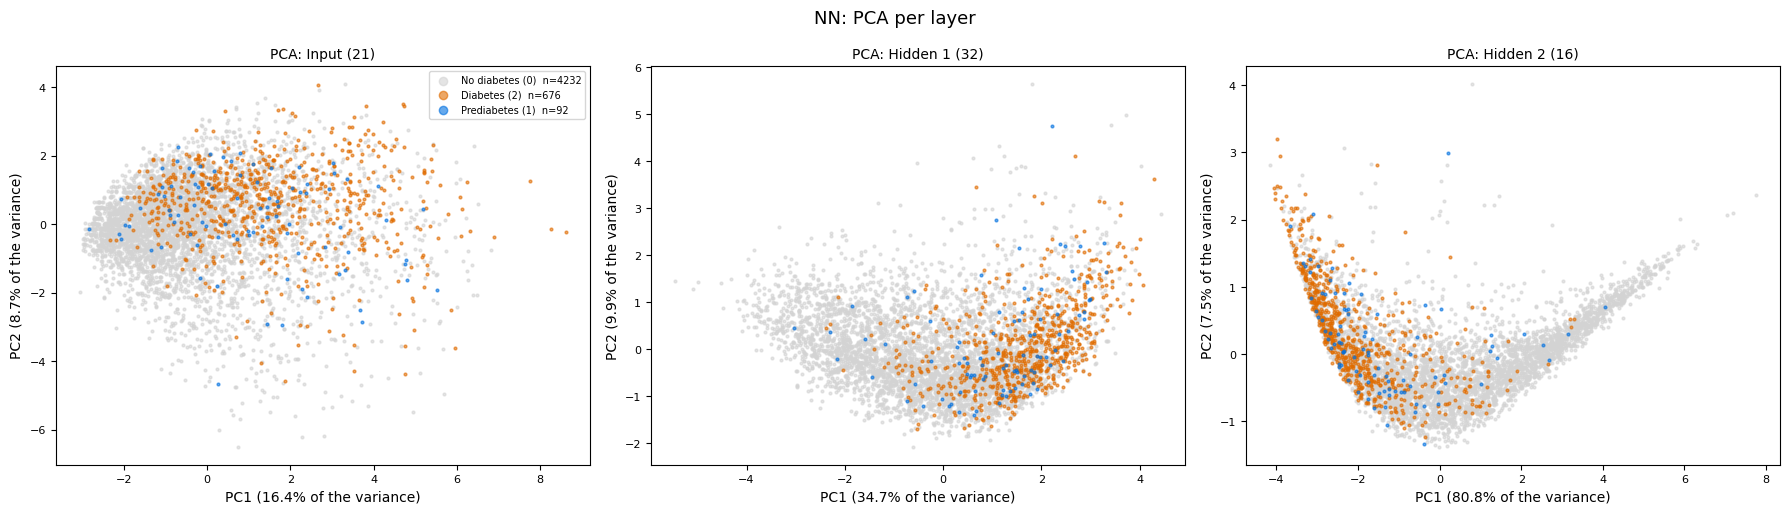

In [6]:
fig, axes = plt.subplots(1, len(reps), figsize=(6 * len(reps), 5.2))
for i, name in enumerate(reps):
    v = pca_vars[name]
    scatter_by_label(axes[i], pca_embs[name], f'PCA: {name}',
                     f'PC1 ({100*v[0]:.1f}% of the variance)', f'PC2 ({100*v[1]:.1f}% of the variance)', legend=(i == 0))
fig.suptitle(f'{MODEL_TAG}: PCA per layer', fontsize=13)
plt.tight_layout()
plt.show()

**Analysis**
- PCA is linear, so it shows the global shape that t-SNE/UMAP can distort. The share of variance on PC1 rises strongly through the network: **16% (input) → 35% (hidden 1) → 81% (hidden 2)**.
- The last hidden layer is therefore almost **one-dimensional**: most of the 16 units vary together along a single direction, and that direction separates healthy from diabetes. This confirms the "risk axis" seen in t-SNE/UMAP, so it is not an artefact of the non-linear methods.
- The bent (boomerang) shape in hidden 2 comes from the ReLU: units that are cut off at 0 for low-risk persons make the cloud fold.

## 5. Conclusion
- The network gradually compresses 21 mostly binary features into a nearly 1-D risk representation (PC1 = 81% of the variance in the last hidden layer).
- Diabetes cases are pushed towards one end of this axis, but the overlap with healthy persons is still large, so the classes are not cleanly separable.
- Prediabetes is not represented as a separate group; it lies between healthy and diabetes, which explains why it is the hardest group to catch.
- Compared with logistic regression (`Project2_LogReg_latent_analysis.ipynb`), the NN actually *reorganizes* the space (islands → one band), whereas logistic regression can only rescale the input axes.